# LLM Fine-Tuning: Domain Adaptation and Instruction Tuning (Starter)

This notebook is the **starter** for the module on domain adaptation and instruction tuning with parameter-efficient fine-tuning. You will work with a small Qwen 2.5 language model equipped with LoRA adapters and explore how domain-adaptive pretraining and instruction tuning change its behavior on simple biomedical-style tasks.

## 1. Learning Objectives

By the end of this notebook, you should be able to:

- Explain the difference between **pretraining**, **domain adaptation**, and **instruction tuning** for large language models (LLMs).
- Describe how **LoRA (Low-Rank Adaptation)** enables parameter-efficient fine-tuning.
- Run a small **domain-adaptive pretraining (DAPT)** loop on a synthetic domain corpus.
- Run a small **instruction-tuning** loop on (instruction, input, output) examples in the same domain.
- Qualitatively and quantitatively compare a base model vs. a domain-adapted + instruction-tuned model.
- Reflect on limitations and safety considerations when adapting LLMs to specialized domains (e.g., biomedical).

## 1. Background: Pretraining and Domain Adaptation

Large Language Models (LLMs) are typically pretrained on massive corpora that span a wide range of modalities such as natural language text, general images, and even video sequences. Pretraining on such diverse data equips the model with broad factual knowledge and general reasoning capabilities that can be reused across many downstream tasks.

However, this broad pretraining data distribution often differs significantly from the data encountered in specialized domains such as biomedicine, chemistry, and other scientific or technical fields. When the source domain of the pretrained model (e.g., web text) is far from the target domain (e.g., biomedical literature), the model’s out-of-the-box performance can be suboptimal.

To bridge this distribution gap, we can **adapt** a pretrained LLM to a specific domain using additional domain-relevant data. This is commonly referred to as **domain adaptation**. In practice, several strategies are used:

- **Domain-Adaptive Pretraining (DAPT)**: continue the self-supervised pretraining objective (e.g., next-token prediction) on a focused in-domain corpus such as research papers, scientific abstracts, or domain-specific documents.
- **Parameter-efficient methods such as Low-Rank Adaptation (LoRA)**: inject domain knowledge by training a relatively small number of additional parameters while keeping the original model weights frozen, greatly reducing compute and memory cost.
- **Supervised fine-tuning / instruction tuning**: use labeled data to further align the model’s behavior with the requirements of downstream applications in the target domain (e.g., domain-specific question answering or reasoning tasks).

In this notebook, we will focus on small-scale demonstrations of these ideas using a simple model, highlighting how domain adaptation and instruction tuning can significantly change the model’s behavior on domain-specific tasks.

### 1.1 Domain-Adaptive Pretraining (DAPT)

**Domain-Adaptive Pretraining (DAPT)** continues the self-supervised next-token prediction training of a pretrained language model, but now on a smaller, focused corpus drawn from a target domain. Instead of updating the model on generic web text, we expose it to in-domain text such as research articles, domain-specific reviews, or other specialized documents.

Examples of domain-specific corpora used in DAPT include:

- Biomedical and clinical research papers (e.g., millions of BioMed articles).
- Computer science papers (e.g., large-scale CS literature collections).
- News articles from curated news datasets.
- Product or service reviews from review platforms.

Empirical studies have shown that continuing pretraining on such domain-specific corpora can substantially improve downstream task performance compared to the original base model. This effect is especially pronounced when the target domain (e.g., biomedical text) is far from the original pretraining distribution. In those settings, DAPT helps the model learn domain terminology, stylistic patterns, and factual regularities that are underrepresented in generic web text.

At a high level, DAPT is still **unsupervised** (or self-supervised): the training signal comes from predicting tokens in the in-domain data rather than from labeled examples. However, it prepares the model to be more effective for subsequent **supervised** fine-tuning steps (such as instruction tuning) on domain-specific tasks.

In practice, DAPT involves design choices and trade-offs:

- How large and diverse the in-domain corpus should be.
- How many additional training steps to run (and with what learning rate).
- How to balance domain specialization with the risk of overfitting or drifting too far from the model’s broad general knowledge.

Despite these trade-offs, DAPT is a powerful and widely used building block in adapting large language models to specialized domains.

### 1.2 Low-Rank Adaptation (LoRA)

As LLMs have grown to tens or hundreds of billions of parameters (and beyond), updating **all** model parameters during fine-tuning has become prohibitively expensive in terms of compute, memory, and engineering complexity. Pretraining such models already requires months of large-scale distributed training; repeating a comparable process for each new domain or task is simply not feasible in most practical settings.

A key insight from prior work is that for many tasks, the number of **effective** parameters that truly need to change is much smaller than the total number of parameters in the model. This idea is sometimes described in terms of an **intrinsic dimension**: the minimum number of parameters required for the model to achieve satisfactory performance on a given objective. Empirically, researchers have shown that by carefully choosing a small set of parameters to update, one can often reach a large fraction of the performance of full-model fine-tuning.

**Low-Rank Adaptation (LoRA)** builds directly on this insight. Instead of updating the full weight matrix $W_0$ in a layer, LoRA keeps $W_0$ **frozen** and learns a low-rank update $\Delta W$ that is added on top:

$$h = W_0 x + \Delta W x,$$

where the update is parameterized as a low-rank decomposition:
$$\Delta W = BA,$$
with $B \in \mathbb{R}^{d \times r}$ and $A \in \mathbb{R}^{r \times k}$, and rank $r$ satisfying $r < \min(d, k)$. Here:

- $d$ is the output dimension of the layer (e.g., the hidden size of the transformer block).
- $k$ is the input dimension of the weight matrix.
- $r$ is a small rank that controls the number of additional parameters.

In this formulation:

- The original weight matrix $W_0$ is fixed (no gradients are applied to it).
- Only the adapter matrices $A$ and $B$ are trained, drastically reducing the number of trainable parameters and the memory footprint required for optimization.

A common initialization strategy is to set the weights of $B$ to zero and initialize $A$ from a Gaussian distribution. At the start of training, this means $\Delta W \approx 0$, so the model behaves like the original pretrained model. As training proceeds, the low-rank update $\Delta W$ learns how to adapt the frozen backbone to the new domain or task.

In practice, LoRA is often applied only to specific parts of the model, such as the projection matrices in the self-attention layers (e.g., $W_q$, $W_k$, $W_v$, and $W_o$ in a transformer). During backpropagation, gradients flow only into the LoRA adapter parameters; the original pretrained parameters remain untouched.

At inference time, the LoRA update can be merged into the base weights (i.e., $W = W_0 + BA$), so that no extra compute is required relative to the original model. Different adapters can be swapped in and out for different domains or tasks without modifying the underlying backbone, which makes LoRA particularly attractive for multi-domain and multi-tenant deployments.

Overall, LoRA provides a powerful **parameter-efficient** mechanism to inject domain knowledge and task-specific behavior into very large pretrained models, without incurring the full cost of end-to-end fine-tuning.

<div style="text-align: center">
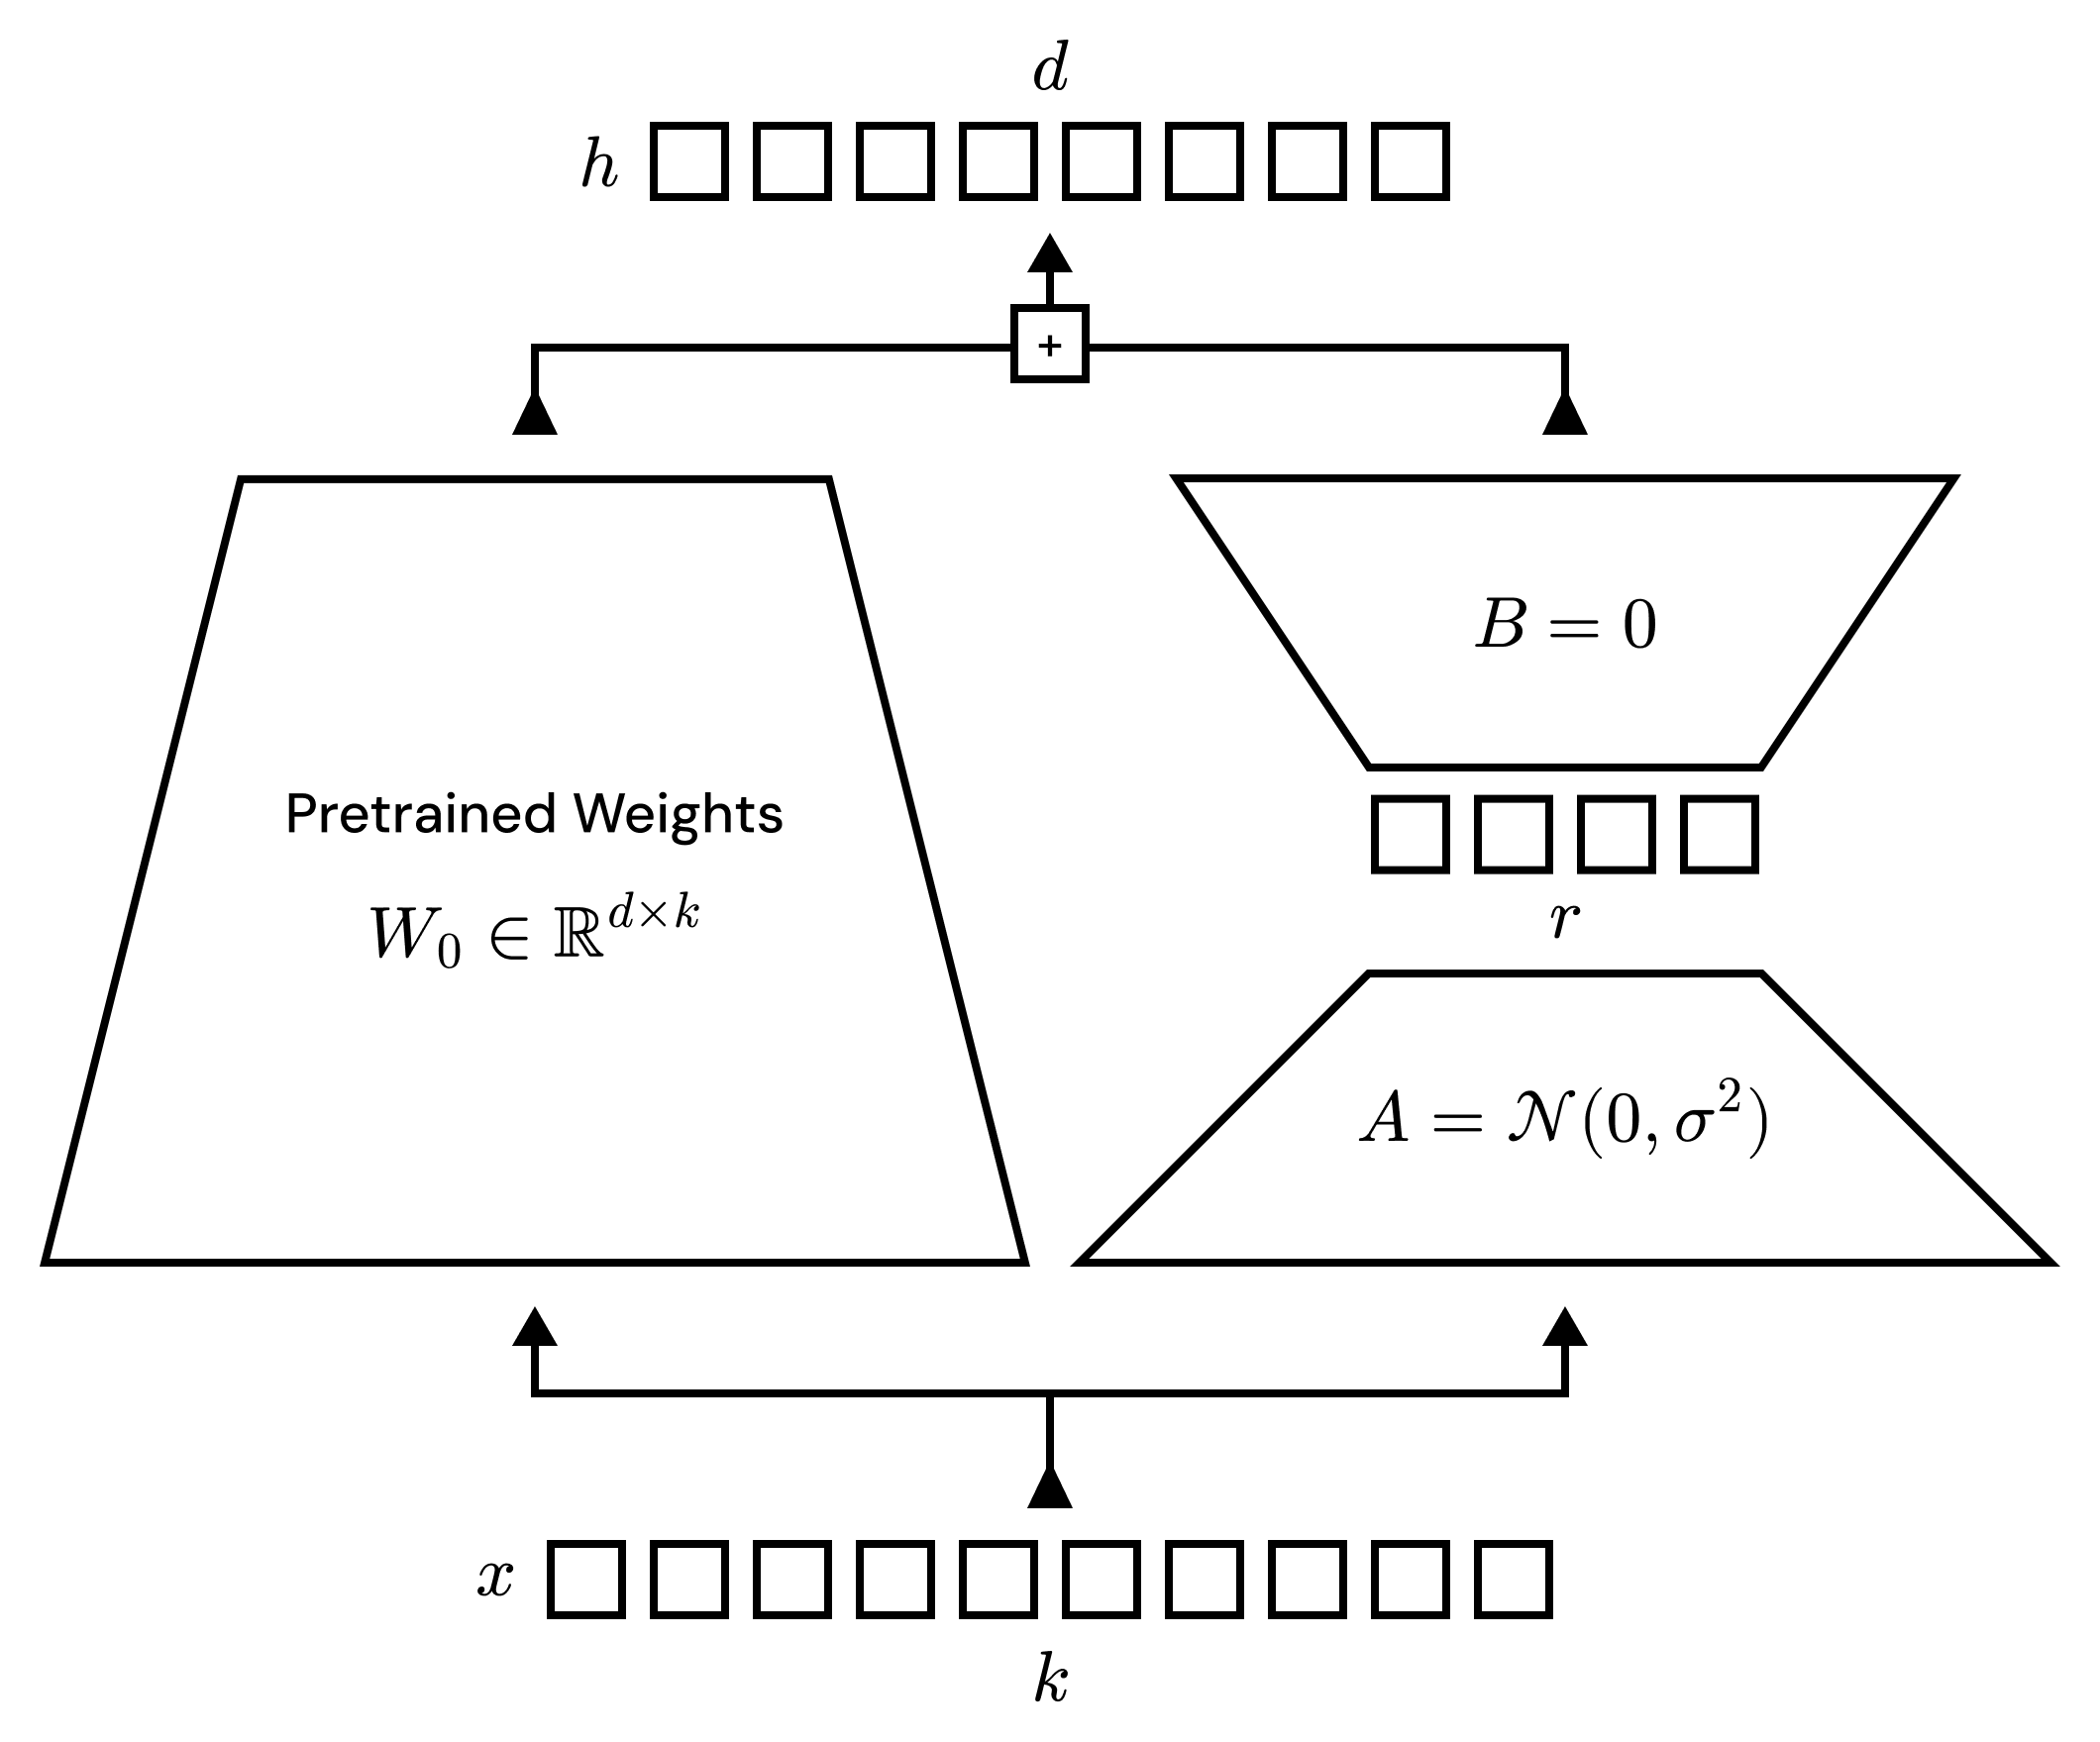
</div>

## 3. Hands-On: Setup and Base Model

- Choose a small, open-source language model suitable for quick experiments.
- Install libraries and load the tokenizer and model.
- Prepare a tiny synthetic or toy dataset for a target domain (e.g., short domain-specific sentences).
- Define simple evaluation prompts to measure behavior before fine-tuning.

In this section you will:

1. Install the required libraries (`transformers`, `peft`, `datasets`, `accelerate`).
2. Load a small **Qwen 2.5** causal language model from Hugging Face.
3. Attach a **LoRA adapter** to its attention projection layers.
4. Define a helper function `generate(...)` for quick text generation.

📝 **TODO (as you read the code below):**
- Identify where the model name is set and how you might swap in a different small Qwen variant.
- Identify which layers receive LoRA adapters and how you might change the rank or dropout to experiment.

In [1]:
# Setup: install and import libraries for LoRA fine-tuning
%pip install -q transformers peft datasets accelerate

# Core libraries
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
from datasets import Dataset

# Pick device: MPS for Apple Silicon, then CUDA, then CPU
device = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
 )
print(f"Using device: {device}")

# Use a small Qwen 2.5 causal LM to keep things lightweight but realistic
model_name = "Qwen/Qwen2.5-0.5B"  # TODO: (optional) try another small Qwen 2.5 variant

# Load tokenizer and base model
tokenizer = AutoTokenizer.from_pretrained(model_name)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.float16 if device in ["cuda", "mps"] else torch.float32
base_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=dtype,
)
base_model.to(device)

# Configure a small LoRA adapter on the attention projections for Qwen-style architecture
lora_config = LoraConfig(
    r=8,  # TODO: (optional) experiment with different LoRA rank values
    lora_alpha=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()


def generate(prompt: str, max_new_tokens: int = 40) -> str:
    """Helper to generate text with the (possibly fine-tuned) model."""
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            top_p=0.95,
            temperature=0.8,
        )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)


# Quick sanity check generation before any fine-tuning
print(generate("In oncology, patients often present with"))


[notice] A new release of pip is available: 26.0 -> 26.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/Users/ppak/GitHub/CMU-AGT/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: mps


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 290/290 [00:00<00:00, 2983.05it/s]
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184
In oncology, patients often present with abnormal vascular permeability due to increased vascular permeability (VMP) and increased vascular permeability, or both. The vascular permeability index (VPI) is used to determine the extent of V


## 4. Hands-On: Simple Domain Adaptation Demo

- Construct a small domain corpus (e.g., mini "research abstracts" or domain-specific descriptions).
- Perform a lightweight domain-adaptive step (continued language modeling or LoRA-based adaptation).
- Track training loss and monitor overfitting signs.
- Evaluate the adapted model vs. the base model on domain-relevant prompts.
- Discuss how this toy example connects back to full-scale DAPT and LoRA.

In this section you will perform a tiny **domain-adaptive pretraining** step on a synthetic biomedical corpus using the LoRA-equipped Qwen model.

The provided code:

1. Defines a small list of domain-specific sentences (`domain_texts`).
2. Wraps them in a Hugging Face `Dataset` and tokenizes with the shared `tokenizer`.
3. Runs a short language-modeling training loop that updates only the LoRA parameters.
4. Tracks the loss in a list `dapt_losses` so you can visualize convergence later.

📝 **TODO:**
- Skim the code and make sure you understand how `tokenize_function`, the `DataLoader`, and the training loop fit together.
- (Optional) Modify `domain_texts` to a different domain (e.g., legal, finance) and observe how generations change after DAPT.
- (Optional) Adjust `max_steps` and see how that affects overfitting and runtime.

In [2]:
# LoRA-based domain-adaptive pretraining on a tiny synthetic corpus
from torch.utils.data import DataLoader

# A tiny "domain" corpus (here: biomedical / clinical-flavored text)
domain_texts = [
    "In this clinical trial, participants received a novel antibody therapy targeting tumor cells.",
    "The kinase inhibitor demonstrated improved progression-free survival in oncology patients.",
    "Genomic sequencing revealed a mutation in the EGFR gene associated with drug resistance.",
    "The randomized study compared standard chemotherapy with an experimental immunotherapy regimen.",
    "Adverse events were monitored throughout the study, including fatigue and neutropenia.",
    "Checkpoint inhibitors were associated with immune-related adverse events such as rash and colitis.",
    "This phase II melanoma trial evaluated a PD-1 inhibitor with objective response rate as the primary endpoint.",
    "Investigators observed durable responses in a subset of patients with high PD-L1 expression.",
]

# Repeat the small corpus a few times so we have enough steps for a visible effect
train_dataset = Dataset.from_dict({"text": domain_texts * 20})


def tokenize_function(example):
    tokens = tokenizer(
        example["text"],
        truncation=True,
        max_length=128,
        padding="max_length",
)
    tokens["labels"] = tokens["input_ids"].copy()
    return tokens


tokenized_dataset = train_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
# Make sure torch tensors are returned so we can move them to the device
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"] )
train_dataloader = DataLoader(tokenized_dataset, batch_size=2, shuffle=True)

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4)

model.train()
num_epochs = 1
max_steps = 50  # keep this tiny so it runs quickly on ~8GB RAM
global_step = 0
dapt_losses = []

for epoch in range(num_epochs):
    for batch in train_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss
        dapt_losses.append(loss.item())
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        global_step += 1

        if global_step % 10 == 0:
            print(f"Domain-adaptive step {global_step} | loss = {loss.item():.4f}")

        if global_step >= max_steps:
            break
    if global_step >= max_steps:
        break

model.eval()
print("\nSample generation after domain-adaptive training:\n")
print(generate("In oncology, patients often present with", max_new_tokens=40))

Map: 100%|██████████| 160/160 [00:00<00:00, 18876.26 examples/s]


Domain-adaptive step 10 | loss = 0.5337
Domain-adaptive step 20 | loss = 0.4343
Domain-adaptive step 30 | loss = 0.3679
Domain-adaptive step 40 | loss = 0.2575


Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


Domain-adaptive step 50 | loss = 0.2378

Sample generation after domain-adaptive training:

In oncology, patients often present with symptoms suggestive of malignancy. A simple blood test can provide valuable information to guide care decisions.


## 5. Hands-On: Simple Instruction Tuning Demo

- Build a tiny instruction dataset (instruction + input → desired output) in the chosen domain.
- Fine-tune the model (or the LoRA adapters) with supervised learning on these instruction pairs.
- Evaluate instruction-following behavior before vs. after instruction tuning.
- Compare effects of domain adaptation alone vs. domain adaptation + instruction tuning.
- Reflect on limitations of the toy example and how it scales in practice.

Next you will build a tiny **instruction-tuning** dataset in the same domain and fine-tune the LoRA adapters further using supervised learning.

The provided code will:

1. Define a small set of (instruction, input, output) triples in an oncology setting.
2. Format them into a unified text prompt that the language model can train on.
3. Run a short supervised fine-tuning loop, tracking losses in `instr_losses`.

📝 **TODO:**
- Read through the instruction examples and make sure you understand the expected responses.
- (Optional) Add at least one new instruction example in the same style.
- (Optional) Change the prompts or outputs to explore how sensitive the model is to wording.

In [3]:
# LoRA-based instruction tuning on top of the domain-adapted model

# Tiny synthetic instruction dataset in the same domain
instruction_examples = [
    {
        "instruction": "Summarize the following oncology abstract in one sentence.",
        "input": "This phase II trial evaluated a PD-1 inhibitor in metastatic melanoma and reported objective response rate and progression-free survival.",
        "output": "One-sentence summary: A phase II trial of a PD-1 inhibitor in metastatic melanoma measured objective response rate and progression-free survival.",
    },
    {
        "instruction": "List two common immune-related adverse events for this therapy.",
        "input": "Patients treated with checkpoint inhibitors frequently reported rash and colitis during the study.",
        "output": "Two common immune-related adverse events are rash and colitis.",
    },
    {
        "instruction": "Explain what a randomized controlled trial is in this context.",
        "input": "Participants were randomly assigned to receive either standard chemotherapy or an experimental antibody therapy.",
        "output": "In this context, a randomized controlled trial randomly assigns participants to different treatment arms to fairly compare outcomes.",
    },
    {
        "instruction": "Provide a simple explanation of progression-free survival.",
        "input": "The primary endpoint of the lung cancer study was progression-free survival at 12 months.",
        "output": "Progression-free survival is how long patients live without their cancer getting worse.",
    },
]


def format_instruction(example: dict) -> str:
    return (
        f"Instruction: {example['instruction']}\n"
        f"Input: {example['input']}\n"
        f"Response: {example['output']}"
    )


instruction_texts = [format_instruction(ex) for ex in instruction_examples]
instruction_dataset = Dataset.from_dict({"text": instruction_texts * 10})  # repeat for a few epochs

instruction_tokenized = instruction_dataset.map(
    tokenize_function, batched=True, remove_columns=["text"]
)
# Ensure we get torch tensors from the dataset so we can move them to the device
instruction_tokenized.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"] )
instruction_dataloader = DataLoader(instruction_tokenized, batch_size=2, shuffle=True)

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4)

model.train()
max_instruction_steps = 50  # again, keep very small for speed
global_step = 0
instr_losses = []

for epoch in range(3):
    for batch in instruction_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss
        instr_losses.append(loss.item())
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        global_step += 1

        if global_step % 10 == 0:
            print(f"Instruction-tuning step {global_step} | loss = {loss.item():.4f}")

        if global_step >= max_instruction_steps:
            break
    if global_step >= max_instruction_steps:
        break

model.eval()
print("\nGeneration on an instruction-style prompt after LoRA + instruction tuning:\n")
print(
    generate(
        "Instruction: Provide a simple explanation of progression-free survival.\n"
        "Input: The primary endpoint of the lung cancer study was progression-free survival at 12 months.\n"
        "Response:",
        max_new_tokens=60,
    )
)

Map: 100%|██████████| 40/40 [00:00<00:00, 10362.70 examples/s]


Instruction-tuning step 10 | loss = 0.2983
Instruction-tuning step 20 | loss = 0.0497
Instruction-tuning step 30 | loss = 0.0231
Instruction-tuning step 40 | loss = 0.0193


Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


Instruction-tuning step 50 | loss = 0.0105

Generation on an instruction-style prompt after LoRA + instruction tuning:

Instruction: Provide a simple explanation of progression-free survival.
Input: The primary endpoint of the lung cancer study was progression-free survival at 12 months.
Response: Progression-free survival is how long patients live without their cancer getting worse.


## 8. Visualizing Training Loss

Both the DAPT and instruction-tuning loops record their losses into `dapt_losses` and `instr_losses`. In this section you will plot these curves to get a rough sense of convergence and overfitting.

📝 **TODO:**
- Run the cell below after you have executed both the DAPT and instruction-tuning cells.
- Inspect the shapes of the curves: do they plateau quickly? Do they fluctuate?
- (Optional) Re-run training with different hyperparameters (e.g., more steps, different learning rate) and compare the curves.

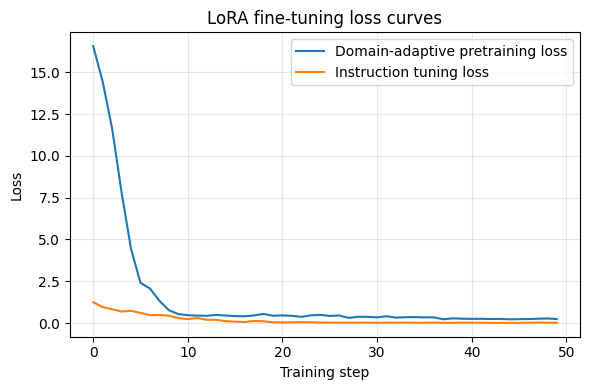

In [4]:
# Visualizing loss curves for domain adaptation and instruction tuning
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
has_any = False

if "dapt_losses" in globals() and dapt_losses:
    plt.plot(dapt_losses, label="Domain-adaptive pretraining loss")
    has_any = True

if "instr_losses" in globals() and instr_losses:
    plt.plot(instr_losses, label="Instruction tuning loss")
    has_any = True

if has_any:
    plt.xlabel("Training step")
    plt.ylabel("Loss")
    plt.title("LoRA fine-tuning loss curves")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No loss data found. Run the domain adaptation and instruction-tuning cells first.")

## 9. Evaluation and Reflection

Finally, you will compare generations from:
- The **base Qwen 2.5 model** (without LoRA updates), and
- The **LoRA-adapted + instruction-tuned model** you trained above.

The code below uses several evaluation prompts, some in-domain (oncology, clinical trials) and one deliberately out-of-domain prompt to probe limitations.

📝 **TODO:**
- Run the evaluation cell and skim the outputs for each prompt.
- For each in-domain prompt, note at least one way the adapted model differs from the base model (better/worse, more/less specific, more/less hallucination).
- For the out-of-domain prompt (baking a chocolate cake), note whether adaptation helped or hurt.
- Summarize your observations in a short paragraph in a new markdown cell below the evaluation.

In [5]:
# Evaluation: compare base model vs LoRA-adapted + instruction-tuned model
from textwrap import indent

# A small set of evaluation prompts
eval_prompts = [
    "Instruction: Summarize the following oncology abstract in one sentence.\n"
    "Input: This phase II trial evaluated a PD-1 inhibitor in metastatic melanoma and reported objective response rate and progression-free survival.\n"
    "Response:",
    "Instruction: List two common immune-related adverse events for this therapy.\n"
    "Input: Patients treated with checkpoint inhibitors frequently reported rash and colitis.\n"
    "Response:",
    "Instruction: Provide a simple explanation of progression-free survival.\n"
    "Input: The primary endpoint of the lung cancer study was progression-free survival at 12 months.\n"
    "Response:",
    "Instruction: Explain what a randomized controlled trial is in this context.\n"
    "Input: Participants were randomly assigned to receive standard chemotherapy or an experimental antibody therapy.\n"
    "Response:",
    "Instruction: Explain how to bake a chocolate cake.\n"
    "Input: A home cook wants clear step-by-step instructions.\n"
    "Response:",
]


def generate_with(model_obj, prompt: str, max_new_tokens: int = 40) -> str:
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model_obj.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            top_p=0.95,
            temperature=0.8,
        )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)


# Reload a fresh base model without LoRA adapters for comparison
base_eval_model = AutoModelForCausalLM.from_pretrained(model_name).to(device)
base_eval_model.eval()

print("=== Evaluation: Base model vs LoRA + instruction-tuned model ===\n")
for i, prompt in enumerate(eval_prompts, start=1):
    print(f"Prompt {i}:")
    print(prompt)
    print()

    base_out = generate_with(base_eval_model, prompt)
    lora_out = generate_with(model, prompt)

    print("Base model:")
    print(indent(base_out, "  "))
    print()
    print("LoRA + instruction-tuned model:")
    print(indent(lora_out, "  "))
    print("\n" + "-" * 80 + "\n")

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 20413.66it/s]
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


=== Evaluation: Base model vs LoRA + instruction-tuned model ===

Prompt 1:
Instruction: Summarize the following oncology abstract in one sentence.
Input: This phase II trial evaluated a PD-1 inhibitor in metastatic melanoma and reported objective response rate and progression-free survival.
Response:



Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


Base model:
  Instruction: Summarize the following oncology abstract in one sentence.
  Input: This phase II trial evaluated a PD-1 inhibitor in metastatic melanoma and reported objective response rate and progression-free survival.
  Response: 21 of 119 patients achieved objective response (ORR) and disease control rate (DCR) and 10 of 119 patients had disease progression. The OR

LoRA + instruction-tuned model:
  Instruction: Summarize the following oncology abstract in one sentence.
  Input: This phase II trial evaluated a PD-1 inhibitor in metastatic melanoma and reported objective response rate and progression-free survival.
  Response: One-sentence summary: A phase II trial of a PD-1 inhibitor in metastatic melanoma measured objective response rate and progression-free survival.

--------------------------------------------------------------------------------

Prompt 2:
Instruction: List two common immune-related adverse events for this therapy.
Input: Patients treated with check

Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


Base model:
  Instruction: List two common immune-related adverse events for this therapy.
  Input: Patients treated with checkpoint inhibitors frequently reported rash and colitis.
  Response: Commonly seen as mild or moderate reactions, with a number of reported side effects reported to include rash, colitis, diarrhea, lymphadenopathy, and rash.

LoRA + instruction-tuned model:
  Instruction: List two common immune-related adverse events for this therapy.
  Input: Patients treated with checkpoint inhibitors frequently reported rash and colitis.
  Response: Two common immune-related adverse events are rash and colitis.

--------------------------------------------------------------------------------

Prompt 3:
Instruction: Provide a simple explanation of progression-free survival.
Input: The primary endpoint of the lung cancer study was progression-free survival at 12 months.
Response:



... (2 outputs left out)

Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


Base model:
  Instruction: Explain what a randomized controlled trial is in this context.
  Input: Participants were randomly assigned to receive standard chemotherapy or an experimental antibody therapy.
  Response: A randomized controlled trial (RCT) is a study design in which the study is randomly assigned participants to either receive a specific intervention or control. In the context of the study, the treatment received by the

LoRA + instruction-tuned model:
  Instruction: Explain what a randomized controlled trial is in this context.
  Input: Participants were randomly assigned to receive standard chemotherapy or an experimental antibody therapy.
  Response: In this context, a randomized controlled trial randomly assigns participants to different treatment arms to fairly compare outcomes.

--------------------------------------------------------------------------------

Prompt 5:
Instruction: Explain how to bake a chocolate cake.
Input: A home cook wants clear step-by-step inst

Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


Base model:
  Instruction: Explain how to bake a chocolate cake.
  Input: A home cook wants clear step-by-step instructions.
  Response: Here are the steps for baking a delicious chocolate cake:

  Ingredients:
  - 1 cup (230g) all-purpose flour
  - 1 teaspoon baking powder
  - 1/2 teaspoon

LoRA + instruction-tuned model:
  Instruction: Explain how to bake a chocolate cake.
  Input: A home cook wants clear step-by-step instructions.
  Response: To bake a chocolate cake, a home cook needs to prepare the batter by combining sugar and flour in a blender until smooth. Then, the batter is spread evenly on a lined cake pan and baked in

--------------------------------------------------------------------------------



## 6. Discussion, Limitations, and Further Reading

In this notebook, you saw a full pipeline that mirrors many real-world workflows, but at toy scale:

- **Domain adaptation (DAPT)** moves a general-purpose language model closer to a target distribution by continuing pretraining on in-domain text. In our case, a small biomedical-style corpus nudged the model to use vocabulary and phrasing that better matches oncology abstracts and clinical notes.
- **LoRA** allowed us to adapt the model by training only a small number of low-rank parameters while keeping the original backbone frozen. This kept the memory and compute footprint small enough to run on a laptop, and made it easy to stack multiple adaptation phases.
- **Instruction tuning** then shaped the domain-adapted model to follow task-style prompts ("Instruction / Input / Response") rather than just predicting the next token on raw text. Even with a tiny dataset, you should see the model become more likely to answer in an instruction-following style.

The qualitative generations in the evaluation cell illustrate these effects: compared to the untouched base model, the DAPT + LoRA + instruction-tuned model tends to:

- Use more domain-relevant vocabulary (e.g., adverse events, progression-free survival) on oncology-style inputs.
- Produce more on-task responses to prompts framed as instructions, rather than generic or drifting continuations.
- Sometimes hallucinate details or over-generalize, especially given the tiny size of the model and training sets.

The loss curves you can plot with the visualization cell give a simple quantitative view:

- During **domain-adaptive pretraining**, the loss should decrease steadily over the first few dozen steps, then flatten as the model overfits the small synthetic corpus.
- During **instruction tuning**, the loss often falls quickly because the model learns the narrow pattern of our templated prompts and answers.
- Because our datasets are so small, a very low loss mostly reflects memorization rather than true generalization.

### Limitations of this toy setup

This demonstration is intentionally small and pedagogical, which introduces several limitations to keep in mind:

- **Model capacity**: `sshleifer/tiny-gpt2` is far too small to capture the richness of real biomedical language or complex reasoning about trials and treatments. The behaviors you see are fragile and often superficial.
- **Data scale and quality**: Both the DAPT corpus and instruction dataset are tiny, synthetic, and highly templated. In practice, you would curate much larger, more diverse, and higher-quality datasets (and carefully de-identify any real clinical text).
- **Overfitting and catastrophic forgetting**: With very small datasets and many repeated epochs, the adapter can overfit to narrow patterns. In larger settings, continued pretraining on one domain can also partially overwrite skills from the original pretraining distribution if not managed carefully.
- **Evaluation**: Here we relied on a few qualitative prompts and a training loss curve. Real systems require held-out test sets, robust automatic metrics, human evaluation, and safety checks (for toxicity, biases, and clinically dangerous hallucinations).
- **Safety and ethics**: Even a well-adapted model can produce plausible but incorrect medical statements. Any system that touches healthcare content must be treated as an assistive tool only, with domain experts in the loop and clear disclaimers.

### Practical considerations and further reading

If you were to scale this up beyond a classroom setting, you would consider:

- Using larger base models and more expressive adapters, while balancing **compute budget** and latency constraints.
- Applying parameter-efficient methods like LoRA, prefix-tuning, or IA³ to support many domains/tasks without storing a full copy of the model for each.
- Designing evaluations that check both **domain competence** and **instruction-following**, including robustness and safety.

For deeper reading, see for example:

- Domain-adaptive pretraining: work on DAPT and TAPT for specialized domains (e.g., biomedical, legal).
- Parameter-efficient tuning: the original LoRA paper and follow-up work on PEFT libraries.
- Instruction tuning: papers on instruction-following LMs (e.g., Flan, T0) and visual instruction tuning (e.g., LLaVA/VIT) for multimodal settings.

These resources, together with the small pipeline in this notebook, provide a starting point for building and critically evaluating domain-specific GPT-style models in your own projects.

## 7. Conclusion

In this notebook, you implemented an end-to-end, parameter-efficient fine-tuning pipeline on top of a small Qwen 2.5 model. You started from a general-purpose causal LM, adapted it to a narrow biomedical/oncology domain with domain-adaptive pretraining, and then trained LoRA adapters further with a tiny instruction-style dataset. Along the way, you inspected loss curves and qualitative generations to see how each phase—DAPT and instruction tuning—changed the model’s behavior.

Although the setup here is intentionally small and simplified, it mirrors real-world design choices: choosing a base model, deciding whether and how to adapt it to a domain, selecting a parameter-efficient method such as LoRA, and then layering instruction tuning on top. You also saw the importance of careful evaluation: looking not only at training loss, but also at how the model responds to in-domain and out-of-domain prompts, and where it still hallucinates or fails.

In practice, scaling this recipe means using larger models, higher-quality and more diverse datasets, and much more rigorous evaluation and safety checks. The core idea, however, remains the same:
- Use domain adaptation (e.g., DAPT) to align a model’s internal representations with the data you care about.
- Use instruction tuning to shape how the model exposes those capabilities to end users via prompts and tasks.
- Use parameter-efficient methods like LoRA to do this in a resource-conscious way, making it feasible to maintain many domain- and task-specific variants.

As you build your own domain-specific GPT-style systems, you can treat this notebook as a template: swap in new domains, tasks, and evaluation criteria, and iterate on the same core pattern of pretraining → domain adaptation → instruction tuning → evaluation.